# English vs Urdu HTML: reproducible evaluation (without an LLM judge)

**Designed specifically for the two uploaded files**: `prompt_set_40_v2.xlsx` and `urdu_rtl_study.zip`.

- **Study design:** 40 prompt IDs (P01–P40) × 2 conditions (English / Urdu) × 2 models (ChatGPT / Claude) × 3 runs = **480 HTML pages**.
- **Task categories:** Forms, Content pages, Tables and dashboards, Interactive.
- **Predefined failure surfaces:** `mixed-script`, `language-heavy`, `layout-dir`, `interactive-focus`.
- **Method:** deterministic DOM checks, browser automation, axe-core WCAG tests, HTML5 parser diagnostics, layout screening, limited high-confidence interaction probes and descriptive/paired statistical plots.
- **No AI evaluator:** no ChatGPT, Claude or other LLM is used to score pages.

> **Experimental caveat.** The English prompts request English interface text and the Urdu prompts request Urdu interface text. Results therefore compare *English-prompted English UIs* and *Urdu-prompted Urdu UIs*, rather than isolating prompt-language effects. Do not claim that prompt language alone caused any difference.

> **Quality caveat.** Automatic tests cannot establish complete WCAG conformance, full functional correctness, linguistic fluency, or bidirectional-text correctness. See the generated manual review template and `README_RESULTS.md`.

This notebook produces **CSV tables, 9 types of figures when relevant, per-prompt paired bootstrap comparisons and a downloadable results ZIP**. Some figures are conditional on successful axe scans and both-language coverage.

## Step 1 — Install Colab dependencies

Run both cells. Browser installation uses Playwright's official Chromium provisioning. Use a fresh Colab Python runtime if installation was interrupted.

In [1]:
%pip -q install "pandas>=2.0" "openpyxl>=3.1" "numpy>=1.24" "matplotlib>=3.7" "beautifulsoup4>=4.12" "html5lib>=1.1" "playwright>=1.46" "requests>=2.28" "tqdm>=4.66"

In [2]:
!python -m playwright install --with-deps chromium

Installing dependencies...
Get:1 https://cli.github.com/packages stable InRelease [3,917 B]
Get:2 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Get:3 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Get:4 https://cli.github.com/packages stable/main amd64 Packages [357 B]
Get:5 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ Packages [81.1 kB]
Hit:6 http://archive.ubuntu.com/ubuntu noble InRelease
Get:7 http://security.ubuntu.com/ubuntu noble-security/main amd64 Packages [1,475 kB]
Get:8 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Get:9 http://security.ubuntu.com/ubuntu noble-security/universe amd64 Packages [1,560 kB]
Get:10 http://security.ubuntu.com/ubuntu noble-security/multiverse amd64 Packages [55.6 kB]
Get:11 http://security.ubuntu.com/ubuntu noble-security/restricted amd64 Packages [2,216 kB]
Get:12 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:13 https://ppa.launchpadconten

## Step 2 — Upload your original files

Upload **both** `prompt_set_40_v2.xlsx` and `urdu_rtl_study.zip` from your computer to Colab. The HTML ZIP is extracted locally; no files are submitted to third-party evaluation APIs.

If the files already exist in `/content`, upload will be skipped.

In [3]:
from pathlib import Path
needed = ["prompt_set_40_v2.xlsx", "urdu_rtl_study.zip"]
missing = [name for name in needed if not (Path("/content")/name).exists()]
if missing:
    from google.colab import files
    print("Please upload:", missing)
    uploaded = files.upload()
    print("Received:", list(uploaded))
for name in needed:
    assert (Path("/content")/name).exists(), f"Missing file: {name}"
    print(name, "|", round((Path("/content")/name).stat().st_size/1024,1), "KB")

Please upload: ['prompt_set_40_v2.xlsx', 'urdu_rtl_study.zip']


Saving urdu_rtl_study.zip to urdu_rtl_study.zip
Saving prompt_set_40_v2.xlsx to prompt_set_40_v2.xlsx
Received: ['urdu_rtl_study.zip', 'prompt_set_40_v2.xlsx']
prompt_set_40_v2.xlsx | 13.1 KB
urdu_rtl_study.zip | 1639.0 KB


## Step 3 — Configure the experimental protocol

The 40 prompt IDs each have explicit, editable structural screening rules derived from your spreadsheet. The *absence* of an expected CSS-detectable element produces a **review flag**, not an automatic declaration that the page failed its prompt. For example, custom widgets may have nonstandard structure and need manual examination.

**Configuration tips:** `MAX_PAGES=12` for an initial smoke test, `None` for all 480 pages; `ENABLE_AXE=True` for real accessibility results; `ALLOW_EXTERNAL_RESOURCES=True` permits external fonts and scripts; setting it to `False` tests self-contained operation but can change visual rendering and behavior. Use the same policy for all conditions. The default mode uses a local HTTP server. A restricted-environment inline-content fallback is recorded explicitly.

Browser probes are deliberately narrow for P17, P32, P35, P37, P38 and P39. All other interactive requirements still need a prompt-specific human/E2E review.

In [4]:
"""Deterministic, non-LLM accessibility and HTML UI audit for prompt_set_40_v2 + urdu_rtl_study.
Designed for Colab; use %pip install -q ... and playwright install chromium before running.
"""
from __future__ import annotations
import collections, hashlib, json, os, re, shutil, socket, threading, time, zipfile
from functools import partial
from pathlib import Path
from http.server import ThreadingHTTPServer, SimpleHTTPRequestHandler

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    import html5lib
except ImportError:
    html5lib = None
from bs4 import BeautifulSoup
from tqdm.auto import tqdm
from playwright.sync_api import sync_playwright

# Configuration: edit these values in Colab. MAX_PAGES=None processes all 480.
CONFIG = {
    'MAX_PAGES': None,
    'ENABLE_AXE': True,
    'ENABLE_INTERACTION_SMOKE': True,
    'VIEWPORTS': [320, 390, 768, 1440],
    'DEFAULT_VIEWPORT': 1440,
    'PAGE_TIMEOUT_MS': 12000,
    'SETTLE_MS': 200,
    'SAVE_SCREENSHOTS': False,
    'SCREENSHOT_LIMIT': 24,
    'ALLOW_EXTERNAL_RESOURCES': True,
    'FORCE_INLINE_HTML': False,  # only for restricted browser sandboxes; Colab normally uses local HTTP
    'AXE_URL': 'https://cdnjs.cloudflare.com/ajax/libs/axe-core/4.10.3/axe.min.js',
    'BOOTSTRAP_REPS': 3000,
    'SEED': 2027,
}

# These checks are *structural proxies* and never an overall prompt-compliance verdict.
# A no-match result is a reviewer flag, not proof that a requirement is absent.
# The requirements are derived from the uploaded English/Urdu prompt pair for each Pxx.
# Format: {prompt_id: [(check_id, check_description, CSS-selectors union, minimum-count), ...]}.
REQUIREMENTS = {
 'P01':[('text_fields','At least two text-entry controls',['input:not([type=hidden]):not([type=checkbox]):not([type=submit])'],2),('checkbox','Remember-me checkbox',['input[type=checkbox], [role=checkbox]'],1),('action','Login action',['button, input[type=submit], [role=button]'],1)],
 'P02':[('fields','Five registration data-entry controls',['input:not([type=hidden]):not([type=submit])'],5),('passwords','Password and confirmation controls',['input[type=password]'],2)],
 'P03':[('fields','Name and email controls',['input:not([type=hidden]):not([type=submit])'],2),('message','Message box',['textarea, [contenteditable=true]'],1)],
 'P04':[('fields','Card number, expiry and CVV entry controls',['input:not([type=hidden]):not([type=submit]), select'],3)],
 'P05':[('details','Personal detail controls',['input:not([type=hidden]):not([type=file])'],2),('cover','Cover-letter entry',['textarea, [contenteditable=true]'],1),('cv','CV upload control',['input[type=file]'],1)],
 'P06':[('fields','Patient / phone / date controls',['input:not([type=hidden]):not([type=submit]), select'],3),('time','Time-slot choice',['input[type=time], select, input[type=radio], [role=listbox]'],1)],
 'P07':[('email','Email entry',['input[type=email], input:not([type])[name*=mail], input[id*=mail]'],1),('submit','Reset submission control',['button, input[type=submit], [role=button]'],1)],
 'P08':[('email','Email entry',['input[type=email], input[name*=mail], input[id*=mail]'],1),('frequency','Frequency choice',['select, input[type=radio], [role=radio], [role=combobox]'],1)],
 'P09':[('details','Personal information fields',['input:not([type=hidden]):not([type=submit])'],2),('program','Program selection',['select, [role=combobox], input[type=radio]'],1)],
 'P10':[('rating','Star rating controls',['input[type=radio], [role=radio], [data-rating], .star, [aria-label*=star]'],5),('comment','Comment box',['textarea, [contenteditable=true]'],1)],
 'P11':[('headline','Hero headline',['h1'],1),('cta','Call-to-action link/button',['button, a[href], [role=button]'],1)],
 'P12':[('about','Portfolio heading',['h1, h2'],1),('projects','Project items',['li, article, .project, [class*=project]'],1),('contact','Contact links',['a[href]'],1)],
 'P13':[('headline','Article headline',['h1'],1),('featured_image','Featured image',['img, picture, svg[role=img]'],1),('body','Multiple body paragraphs',['p'],3)],
 'P14':[('nav','Top navigation',['nav, [role=navigation]'],1),('banner','University banner/heading',['h1, header, [class*=hero], [class*=banner]'],1),('sections','Programs/news section headings',['h2, h3'],2)],
 'P15':[('dishes','Multiple dish items',['li, article, .menu-item, [class*=dish], [class*=menu-item]'],2)],
 'P16':[('title','Product heading',['h1, h2'],1),('features','Feature list',['li'],2)],
 'P17':[('questions','At least two FAQ question controls',['details summary, button, [role=button], [aria-expanded]'],2)],
 'P18':[('intro','Event introduction',['p'],1),('speakers','Speaker list structure',['li, article, [class*=speaker]'],2),('schedule','Schedule structure',['table, time, [class*=schedule], [class*=session]'],1)],
 'P19':[('headline','About-us heading',['h1'],1),('body','History/mission/departments content',['p'],3)],
 'P20':[('message','Error heading',['h1, h2'],1),('home','Link back to home',['a[href]'],1)],
 'P21':[('tabular','Results table/grid',['table, [role=table], [role=grid]'],1),('columns','At least four column headers',['th, [role=columnheader]'],4)],
 'P22':[('summary','Three summary card-like elements',['article, [class*=card], [class*=stat], [class*=metric], [role=group]'],3)],
 'P23':[('cart','Cart item elements',['tr, li, [class*=item], [class*=product]'],2)],
 'P24':[('forecast','Multiple forecast cards/rows',['tr, li, article, [class*=day], [class*=forecast]'],5)],
 'P25':[('tabular','Bank statement table/grid',['table, [role=table], [role=grid]'],1),('columns','Date, description, debit, credit and balance headers',['th, [role=columnheader]'],5)],
 'P26':[('tabular','Attendance table/grid',['table, [role=table], [role=grid]'],1),('columns','Employee plus weekday headers',['th, [role=columnheader]'],6)],
 'P27':[('details','Profile details',['p, dl, [class*=profile]'],1),('toggle','Settings toggle',['input[type=checkbox], [role=switch], [role=checkbox]'],1)],
 'P28':[('steps','Four order progress steps',['li, [class*=step], [class*=stage], [class*=status]'],4)],
 'P29':[('messages','Multiple notifications',['li, article, [class*=notification]'],3)],
 'P30':[('courses','Course cards',['article, [class*=course], [class*=card]'],2),('filters','Two filter controls',['select, [role=combobox], [class*=filter] select, [class*=filter] button'],2)],
 'P31':[('choices','Multiple-choice answer controls',['input[type=radio], [role=radio], button'],2)],
 'P32':[('task_input','Task entry',['input:not([type=hidden]), textarea'],1),('action','Add task action',['button, [role=button]'],1)],
 'P33':[('keys','Calculator number/operator buttons',['button, [role=button], input[type=button]'],10),('display','Calculator output display',['output, input[readonly], [class*=display], [class*=screen], [id*=display]'],1)],
 'P34':[('images','Multiple gallery thumbnails',['img, picture'],2)],
 'P35':[('nav','Navigation structure',['nav, [role=navigation]'],1),('dropdown','Dropdown control or menu',['button, [aria-haspopup], details summary, [class*=dropdown]'],1)],
 'P36':[('messages','Incoming/outgoing message bubbles',['[class*=message], [class*=bubble], li'],2),('compose','Message input',['input:not([type=hidden]), textarea, [contenteditable=true]'],1)],
 'P37':[('options','Cancel and delete actions',['button, [role=button]'],2)],
 'P38':[('tabs','Three tab controls',['[role=tab], button, [class*=tab]'],3)],
 'P39':[('date_widget','Calendar/date input',['input[type=date], [role=grid], [class*=calendar], [class*=datepicker], [class*=date-picker]'],1)],
 'P40':[('search','Search box',['input[type=search], input[type=text], input:not([type])'],1),('results','Text results list',['li, article, [class*=result]'],1)],
}

## Step 4 — Parse and verify the dataset

The extraction indexes each page from its **folder path** rather than relying on inconsistent filenames. Two P21 run numbers are absent from filenames; they are inferred from the remaining run-number slots and flagged as `run_inferred=True`. The study is expected to yield 160 model × language × prompt combinations with three runs each.

In [5]:
def _status_series(rows, id_col='prompt_id'):
    return collections.Counter(row[id_col] for row in rows)


def locate_inputs(search_dir='/content'):
    places = [Path(search_dir), Path('/mnt/data'), Path.cwd()]
    names = ['prompt_set_40_v2.xlsx', 'urdu_rtl_study.zip']
    result = {}
    for name in names:
        for directory in places:
            candidate = directory / name
            if candidate.exists():
                result[name] = candidate
                break
    if len(result) != 2:
        raise FileNotFoundError('Upload prompt_set_40_v2.xlsx and urdu_rtl_study.zip to Colab and rerun. Found: '+str(result))
    return result


def build_manifest(xlsx, zip_path, work_dir, out_dir):
    prompts = pd.read_excel(xlsx, engine='openpyxl').rename(columns=lambda v: str(v).strip().lower())
    required_columns = ['id', 'category', 'failure_surface', 'english_prompt', 'urdu_prompt']
    if not set(required_columns).issubset(prompts.columns):
        raise ValueError(f'Prompt columns missing: {set(required_columns)-set(prompts.columns)}')
    prompts['id'] = prompts['id'].astype(str).str.upper().str.strip()
    if len(prompts)!=40 or prompts['id'].nunique()!=40:
        raise ValueError('Expected 40 unique prompt IDs.')
    if set(REQUIREMENTS) != set(prompts.id):
        raise ValueError('Requirement protocol IDs do not match input spreadsheet.')
    prompt_index = prompts.set_index('id').to_dict('index')
    work_dir = Path(work_dir); out_dir=Path(out_dir)
    work_dir.mkdir(parents=True,exist_ok=True); out_dir.mkdir(parents=True,exist_ok=True)
    root = work_dir/'html'; root.mkdir(exist_ok=True)
    groups=collections.defaultdict(list)
    with zipfile.ZipFile(zip_path) as z:
        for entry in z.infolist():
            if entry.is_dir() or not entry.filename.lower().endswith('.html'):
                continue
            path=Path(entry.filename)
            if '..' in path.parts or path.is_absolute():
                raise ValueError('Unsafe ZIP path: '+entry.filename)
            match=re.search(r'/(P\d{2})/(english|urdu)/(chatgpt|claude)/[^/]+\.html$', '/'+entry.filename,re.I)
            if not match:
                raise ValueError('Unexpected ZIP layout: '+entry.filename)
            pid,language,model=match.group(1).upper(),match.group(2).lower(),match.group(3).lower()
            if pid not in prompt_index: raise ValueError('Unknown prompt '+pid)
            filename=path.name
            run_match=re.search(r'run[_-]?0*([123])(?=\D|$)',filename,re.I)
            run=int(run_match.group(1)) if run_match else None
            dest=root/pid/language/model/filename
            dest.parent.mkdir(parents=True,exist_ok=True)
            dest.write_bytes(z.read(entry))
            groups[(pid,language,model)].append(dict(prompt_id=pid,language=language,model=model,run=run,run_inferred=False,path=dest,source_name=entry.filename))
    rows=[]
    for key in sorted(groups):
        entries=groups[key]
        if len(entries)!=3:
            raise ValueError(f'Expected three runs, found {len(entries)} for {key}')
        known=[r['run'] for r in entries if r['run'] is not None]
        if len(set(known))!=len(known):
            raise ValueError('Duplicate run labels for '+str(key))
        remaining=sorted(set([1,2,3])-set(known))
        missing=sorted((r for r in entries if r['run'] is None),key=lambda r:r['source_name'])
        if len(remaining)!=len(missing):
            raise ValueError('Cannot infer unlabeled runs: '+str(key))
        for item,number in zip(missing,remaining):
            item['run']=number;item['run_inferred']=True
        for entry in sorted(entries,key=lambda r:r['run']):
            p=prompt_index[entry['prompt_id']]
            entry.update(category=p['category'],failure_surface=p['failure_surface'],prompt=str(p[entry['language']+'_prompt']))
            entry['page_id']=f"{entry['prompt_id']}_{entry['language']}_{entry['model']}_run{entry['run']}"
            entry['sha256']=hashlib.sha256(entry['path'].read_bytes()).hexdigest()
            rows.append(entry)
    manifest=pd.DataFrame(rows).sort_values(['prompt_id','language','model','run']).reset_index(drop=True)
    if len(manifest)!=480:raise ValueError(f'Expected 480 HTML pages, found {len(manifest)}')
    manifest.assign(path=manifest['path'].astype(str)).to_csv(out_dir/'manifest.csv',index=False,encoding='utf-8-sig')
    print(f'Manifest: {len(manifest)} pages, {manifest.sha256.nunique()} distinct hashes; inferred runs: {manifest.run_inferred.sum()}')
    return manifest,prompts,root


def static_checks(html_text,language):
    soup=BeautifulSoup(html_text,'html.parser')
    root=soup.html
    doc_lang=str(root.get('lang','')).lower() if root else ''
    doc_dir=str(root.get('dir','')).lower() if root else ''
    parse_errors=np.nan
    if html5lib is not None:
        try:
            parser=html5lib.HTMLParser(strict=False)
            parser.parse(html_text)
            parse_errors=len(parser.errors)
        except Exception:
            pass
    return {
        'bytes_utf8':len(html_text.encode('utf-8')),
        'has_doctype':bool(re.search(r'<!doctype\s+html\s*>',html_text,re.I)),
        'has_viewport_meta':bool(soup.select_one('meta[name="viewport"]')),
        'lang_correct':doc_lang==('ur' if language=='urdu' else 'en'),
        'document_dir':doc_dir or 'implicit-ltr',
        'base_dir_correct':doc_dir=='rtl' if language=='urdu' else doc_dir!='rtl',
        'fenced_code':bool(re.search(r'^\s*```',html_text)),
        'html5_parse_diagnostics':parse_errors,
        'external_url_mentions':len(re.findall(r'https?://',html_text,re.I)),
        'form_count':len(soup.select('form')),
        'button_count':len(soup.select('button')),
        'input_count':len(soup.select('input:not([type=hidden])')),
    }


def structural_requirement_checks(page_id,pid,rendered_html):
    soup=BeautifulSoup(rendered_html,'html.parser')
    rows=[]
    for check_id,descr,selectors,minimum in REQUIREMENTS[pid]:
        observed=set()
        for selector in selectors:
            try:
                for el in soup.select(selector):
                    observed.add(id(el))
            except Exception as exc:
                raise ValueError(f'Bad selector in {pid}/{check_id}: {selector}') from exc
        count=len(observed)
        rows.append({'page_id':page_id,'prompt_id':pid,'check_id':check_id,'description':descr,
                     'selector':' | '.join(selectors),'required_min':minimum,'observed':count,
                     'evidence_found':int(count>=minimum),
                     'status':'evidence_found' if count>=minimum else 'review_no_evidence'})
    return rows

## Step 5 — Non-LLM browser checks

Each generated page is loaded in an isolated browser context. The audit collects:

- **axe-core WCAG A/AA findings:** distinct rule IDs, severities, affected node counts and incomplete/manual-review rules.
- **Browser health:** JavaScript exceptions and load failures (never recorded as zero violations).
- **Accessibility proxy:** potential HTML controls without conventional labels; axe is authoritative for tested rules, while this proxy is only a reviewer flag.
- **RTL and text:** document `lang`/`dir`, computed direction and script distribution (not Urdu linguistic accuracy).
- **Layout:** horizontal overflow and clipped visible controls at 320, 390, 768 and 1440 CSS px. Tables have possible WCAG reflow exceptions.
- **Interactive smoke probes:** narrow scenarios when a reliable widget pattern is detected; otherwise `not_tested`/`review`.

Font/network dependencies and browser environment should be recorded consistently; any rendering under blocked external resources must be reported as such.

In [6]:
# Browser evaluation. These are flags requiring review, not definitive WCAG conformance statements.
BROWSER_INSPECT_JS=r"""() => {
 const visible = el => { const r=el.getBoundingClientRect(),s=getComputedStyle(el);
   return r.width>0 && r.height>0 && s.display!=='none' && s.visibility!=='hidden'; };
 const all=[...document.querySelectorAll('body *')];
 const editable=all.filter(el=>el.matches('input:not([type=hidden]), select, textarea'));
 const unlabelled=editable.filter(el => {
   if (!visible(el) || ['submit','button','reset','image'].includes((el.getAttribute('type')||'').toLowerCase())) return false;
   return !(el.labels?.length || el.getAttribute('aria-label')?.trim() ||
    (el.getAttribute('aria-labelledby')||'').split(/\s+/).some(id=>id && document.getElementById(id)?.textContent?.trim()) ||
    el.getAttribute('title')?.trim());
 });
 const controls=all.filter(el => el.matches('button, input, select, textarea, a[href], [role=button], [role=tab], [role=checkbox]') && visible(el));
 const viewport=window.innerWidth;
 const clipped=controls.filter(el => { const r=el.getBoundingClientRect();return r.right>viewport+3 || r.left< -3; });
 const scroll = Math.max(document.documentElement.scrollWidth, document.body.scrollWidth);
 const text = document.body ? document.body.innerText : '';
 return {viewport_width:viewport, scroll_width:scroll, overflow_px:Math.max(0,scroll-viewport),
   clipped_controls:clipped.length, visible_controls:controls.length,
   unlabelled_controls_proxy:unlabelled.length, labelled_controls_proxy:editable.filter(visible).length-unlabelled.length,
   total_entry_controls:editable.filter(visible).length,
   text_sample:text.slice(0,8000),
   document_lang:document.documentElement.lang||'', computed_direction:getComputedStyle(document.documentElement).direction,
   page_title:document.title,
   body_characters:text.length};
}"""

AXE_RUN_JS=r"""async () => {
  if (typeof window.axe === 'undefined') throw new Error('axe-core not present in document');
  const res=await window.axe.run(document, {
    runOnly:{type:'tag',values:['wcag2a','wcag2aa','wcag21a','wcag21aa','wcag22aa']},
    resultTypes:['violations','incomplete','inapplicable','passes']
  });
  return {engine:res.testEngine?.version || '', incomplete_rules:res.incomplete.length,
    violations:res.violations.map(v=>({rule_id:v.id,impact:v.impact||'unknown',description:v.help,
      help_url:v.helpUrl,nodes:v.nodes.map(n=>({target:n.target.join(' '),html:n.html?.slice(0,300)}))}))};
}"""


def urdu_letter_share(text):
    # Descriptive Unicode-script proxy only. NOT translation quality or linguistic correctness.
    if not text:return np.nan
    arabic=sum(1 for c in text if ('\u0600'<=c<='\u06FF' or '\u0750'<=c<='\u077F' or '\u08A0'<=c<='\u08FF') and c.isalpha())
    latin=sum(1 for c in text if ('A'<=c<='Z' or 'a'<=c<='z'))
    return arabic/(arabic+latin) if (arabic+latin) else np.nan


def keyboard_smoke(page):
    try:
        page.keyboard.press('Tab',timeout=1800)
        return bool(page.evaluate("() => document.activeElement && document.activeElement !== document.body && document.activeElement !== document.documentElement"))
    except Exception:return None


def interaction_probe(page,pid):
    """Narrow, high-confidence probes. Unrecognized implementations are NOT_TESTED, never failed.
    A successful probe is not evidence that every feature of the widget works."""
    try:
        if pid=='P17':
            q=page.locator('details > summary').first
            if q.count():
                details=page.locator('details').first
                before=details.evaluate('(e)=>e.open')
                q.click(timeout=2200)
                after=details.evaluate('(e)=>e.open')
                return 'pass' if after!=before else 'fail','FAQ native <details> expands/collapses'
            q=page.locator('[aria-expanded]').first
            if q.count():
                before=q.get_attribute('aria-expanded');q.click(timeout=2200)
                after=q.get_attribute('aria-expanded')
                return ('pass' if after!=before else 'fail'),'FAQ aria-expanded toggle'
            return 'not_tested','FAQ custom accordion requires targeted human test'
        if pid=='P38':
            tabs=page.locator('[role="tab"]')
            if tabs.count()>=3:
                second=tabs.nth(1)
                second.click(timeout=2200)
                return ('pass' if second.get_attribute('aria-selected')=='true' else 'review'),'Second ARIA tab selected'
            return 'not_tested','Custom tabs require task-specific test'
        if pid=='P35':
            q=page.locator('[aria-haspopup][aria-expanded]').first
            if q.count():
                before=q.get_attribute('aria-expanded');q.click(timeout=2200)
                after=q.get_attribute('aria-expanded')
                return ('pass' if after!=before else 'fail'),'Dropdown state changes on activation'
            return 'not_tested','No standard expanded-state dropdown detected'
        if pid=='P37':
            dialog=page.locator('[role="dialog"], dialog[open]')
            if dialog.count():
                return 'review','Dialog found; cancel/delete outcomes require contextual test'
            return 'not_tested','Custom dialog needs contextual outcome test'
        if pid=='P39':
            q=page.locator('input[type="date"]').first
            if q.count():
                q.fill('2027-03-15',timeout=2200)
                val=q.input_value()
                return ('pass' if val=='2027-03-15' else 'fail'),'Native date widget accepts date'
            return 'not_tested','Custom calendar needs date-selection test'
        if pid=='P32':
            q=page.locator('input[type="text"], input:not([type])').first
            add=page.get_by_role('button', name=re.compile(r'add|اضافہ|شامل|\+',re.I)).first
            if q.count() and add.count():
                token='EVAL_TASK_732519'
                q.fill(token,timeout=2200);add.click(timeout=2200)
                found=token in page.locator('body').inner_text(timeout=2200)
                return ('pass' if found else 'fail'),'Add-task action inserts entered text'
            return 'not_tested','To-do controls not reliably matched; manual interaction test'
        return 'not_applicable','No generic behavioral probe defined for this prompt'
    except Exception as exc:
        return 'review',f'Interaction probe exception (review): {str(exc)[:160]}'


def _serve(root):
    class QuietHandler(SimpleHTTPRequestHandler):
        def log_message(self,fmt,*args):pass
    def handler(*a,**k):return QuietHandler(*a,directory=str(root),**k)
    server=ThreadingHTTPServer(('127.0.0.1',0),handler)
    thread=threading.Thread(target=server.serve_forever,daemon=True);thread.start()
    return server


def load_axe_script(cfg,work_dir):
    if not cfg['ENABLE_AXE']:return None
    import requests
    axe_path=Path(work_dir)/'axe.min.js'
    if not axe_path.exists():
        resp=requests.get(cfg['AXE_URL'],timeout=45)
        resp.raise_for_status()
        if len(resp.content)<100000 or b'axe' not in resp.content[:2000]:
            raise RuntimeError('Invalid axe-core JavaScript download; do not silently report zero violations')
        axe_path.write_bytes(resp.content)
    return axe_path.read_text(encoding='utf8')


def run_evaluation(manifest,html_root,work_dir,out_dir,cfg=None):
    cfg={**CONFIG,**(cfg or {})}
    out_dir=Path(out_dir);work_dir=Path(work_dir)
    out_dir.mkdir(parents=True,exist_ok=True)
    axe_js=load_axe_script(cfg,work_dir)
    server=_serve(html_root)
    base=f'http://127.0.0.1:{server.server_address[1]}/'
    data=[]; req_rows=[]; axe_rows=[]; interaction_rows=[]; responsive=[]
    count_shots=0
    subset=manifest.head(cfg['MAX_PAGES']) if cfg['MAX_PAGES'] else manifest
    # Balanced screenshots across task categories, models and languages.
    screenshot_ids=set(subset.groupby(['category','model','language'],sort=False).head(1).page_id)
    started=time.monotonic()
    try:
        with sync_playwright() as pw:
            options={'headless':True,'args':['--no-sandbox','--disable-dev-shm-usage']}
            if os.path.exists('/usr/bin/chromium'):
                options['executable_path']='/usr/bin/chromium'
            browser=pw.chromium.launch(**options)
            print('Browser version:',browser.version)
            for _,r in tqdm(subset.iterrows(),total=len(subset),desc='Auditing HTML'):
                url=base+f"{r['prompt_id']}/{r['language']}/{r['model']}/{r['path'].name}"
                page_record={k:r[k] for k in ['page_id','prompt_id','category','failure_surface','model','language','run','sha256','run_inferred']}
                html_src=r['path'].read_text(encoding='utf-8',errors='replace')
                page_record.update(static_checks(html_src,r['language']))
                page_record.update({'load_ok':False,'axe_status':'not_run','axe_rule_count':np.nan,
                                    'axe_affected_nodes':np.nan,'axe_serious_critical_nodes':np.nan,
                                    'axe_incomplete_rules':np.nan,'js_exception_count':np.nan,
                                    'keyboard_smoke_status':'not_run','interaction_status':'not_run',
                                    'layout_320_overflow_px':np.nan,'layout_390_overflow_px':np.nan,
                                    'layout_768_overflow_px':np.nan,'layout_1440_overflow_px':np.nan,
                                    'structural_evidence_pct':np.nan})
                context=browser.new_context(viewport={'width':cfg['DEFAULT_VIEWPORT'],'height':900},
                                            bypass_csp=True,reduced_motion='reduce',
                                            locale='ur-PK' if r['language']=='urdu' else 'en-US')
                page=context.new_page()
                errors=[]
                page.on('pageerror',lambda error: errors.append(str(error)[:300]))
                try:
                    if not cfg['ALLOW_EXTERNAL_RESOURCES']:
                        page.route('**/*',lambda route: route.continue_() if route.request.url.startswith(base) else route.abort())
                    # Some sandboxes block loopback HTTP; set_content is a safe
                    # single-file fallback, but relative assets may not resolve.
                    try:
                        if cfg.get('FORCE_INLINE_HTML'):
                            page.set_content(html_src,wait_until='domcontentloaded',timeout=cfg['PAGE_TIMEOUT_MS'])
                            page_record['load_mode']='set_content_fallback'
                        else:
                            page.goto(url,wait_until='domcontentloaded',timeout=cfg['PAGE_TIMEOUT_MS'])
                            page_record['load_mode']='local_http'
                    except Exception as nav_exc:
                        if 'ERR_BLOCKED_BY_ADMINISTRATOR' in str(nav_exc) or 'ERR_CONNECTION_REFUSED' in str(nav_exc):
                            page.close()
                            page=context.new_page()
                            page.on('pageerror',lambda error:errors.append(str(error)[:300]))
                            if not cfg['ALLOW_EXTERNAL_RESOURCES']:
                                page.route('**/*',lambda route: route.continue_() if route.request.url.startswith(base) else route.abort())
                            page.set_content(html_src,wait_until='domcontentloaded',timeout=cfg['PAGE_TIMEOUT_MS'])
                            page_record['load_mode']='set_content_fallback'
                        else:
                            raise
                    page.wait_for_timeout(cfg['SETTLE_MS'])
                    page_record['load_ok']=True
                    view=page.evaluate(BROWSER_INSPECT_JS)
                    page_record.update({
                        'body_characters':view['body_characters'],'visible_controls':view['visible_controls'],
                        'unlabelled_controls_proxy':view['unlabelled_controls_proxy'],
                        'total_entry_controls':view['total_entry_controls'],
                        'computed_direction':view['computed_direction'],
                        'urdu_letter_share':urdu_letter_share(view['text_sample']),
                    })
                    rendered_html=page.content()
                    rules=structural_requirement_checks(r['page_id'],r['prompt_id'],rendered_html)
                    req_rows.extend(rules)
                    page_record['structural_evidence_pct']=100*np.mean([rr['evidence_found'] for rr in rules]) if rules else np.nan
                    page_record['structural_checks_total']=len(rules)
                    page_record['structural_checks_no_evidence']=sum(1 for rr in rules if rr['evidence_found']==0)
                    keyboard_check=keyboard_smoke(page) if view['visible_controls'] else None
                    page_record['keyboard_smoke_status']=('pass' if keyboard_check is True else ('review' if keyboard_check is False else 'not_applicable'))
                    # Reset page to original state before auditing accessibility and behavior.
                    if page_record.get('load_mode')=='set_content_fallback':
                        page.set_content(html_src,wait_until='domcontentloaded',timeout=cfg['PAGE_TIMEOUT_MS'])
                    else:
                        page.reload(wait_until='domcontentloaded',timeout=cfg['PAGE_TIMEOUT_MS'])
                    page.wait_for_timeout(cfg['SETTLE_MS'])
                    if axe_js:
                        try:
                            page.add_script_tag(content=axe_js)
                            axe=page.evaluate(AXE_RUN_JS)
                            page_record['axe_status']='ok';page_record['axe_version']=axe['engine']
                            page_record['axe_rule_count']=len(axe['violations'])
                            page_record['axe_affected_nodes']=sum(len(v['nodes']) for v in axe['violations'])
                            page_record['axe_serious_critical_nodes']=sum(len(v['nodes']) for v in axe['violations'] if v['impact'] in ('serious','critical'))
                            page_record['axe_incomplete_rules']=axe['incomplete_rules']
                            for v in axe['violations']:
                                axe_rows.append({'page_id':r['page_id'],'prompt_id':r['prompt_id'],'language':r['language'],
                                                 'model':r['model'],'run':r['run'],'rule_id':v['rule_id'],
                                                 'impact':v['impact'],'description':v['description'],
                                                 'affected_nodes':len(v['nodes']), 'example_target':v['nodes'][0]['target'] if v['nodes'] else '',
                                                 'help_url':v['help_url']})
                        except Exception as e:
                            page_record['axe_status']='error';page_record['axe_error']=str(e)[:400]
                    for width in cfg['VIEWPORTS']:
                        page.set_viewport_size({'width':width,'height':900})
                        page.wait_for_timeout(60)
                        v=page.evaluate(BROWSER_INSPECT_JS)
                        responsive.append({'page_id':r['page_id'],'prompt_id':r['prompt_id'],'language':r['language'],
                                           'model':r['model'],'run':r['run'],'viewport':width,
                                           'overflow_px':v['overflow_px'],'clipped_controls':v['clipped_controls'],
                                           'visible_controls':v['visible_controls']})
                        page_record[f'layout_{width}_overflow_px']=v['overflow_px']
                        page_record[f'layout_{width}_clipped_controls']=v['clipped_controls']
                    page.set_viewport_size({'width':cfg['DEFAULT_VIEWPORT'],'height':900})
                    if cfg['SAVE_SCREENSHOTS'] and r['page_id'] in screenshot_ids and count_shots<cfg['SCREENSHOT_LIMIT']:
                        shot_dir=out_dir/'screenshots';shot_dir.mkdir(exist_ok=True)
                        page.screenshot(path=str(shot_dir/(r['page_id']+'.png')),full_page=True,timeout=5000)
                        count_shots+=1
                    if cfg['ENABLE_INTERACTION_SMOKE']:
                        status,detail=interaction_probe(page,r['prompt_id'])
                        page_record['interaction_status']=status
                        interaction_rows.append({'page_id':r['page_id'],'prompt_id':r['prompt_id'],
                                                 'language':r['language'],'model':r['model'],
                                                 'status':status,'detail':detail})
                except Exception as e:
                    page_record['processing_error']=str(e)[:500]
                finally:
                    page_record['js_exception_count']=len(errors)
                    page_record['js_exception_example']=errors[0] if errors else ''
                    data.append(page_record)
                    page.close();context.close()
            browser.close()
    finally:
        server.shutdown();server.server_close()
    metrics=pd.DataFrame(data);req_df=pd.DataFrame(req_rows);axe_df=pd.DataFrame(axe_rows);inter_df=pd.DataFrame(interaction_rows);resp_df=pd.DataFrame(responsive)
    for name,df in [('page_metrics',metrics),('structural_requirement_checks',req_df),('axe_violations',axe_df),
                    ('interaction_probes',inter_df),('responsive_results',resp_df)]:
        df.to_csv(out_dir/(name+'.csv'),index=False,encoding='utf-8-sig')
    print(f'Audited {len(metrics)} pages in {(time.monotonic()-started)/60:.1f} minutes; '
          f'page-load failures: {(~metrics.load_ok).sum()}; axe scan failures: {(metrics.axe_status=="error").sum()}')
    return metrics,req_df,axe_df,inter_df,resp_df

## Step 6 — Visualization and paired statistics

Figures include structural evidence, accessibility findings, serious/critical violations, common axe rules, metadata, responsive overflow, failure surfaces, prompt-level paired differences and JavaScript runtime errors.

**Unit of inference:** comparisons are paired by **prompt ID**, taking the mean across three runs within each model–language condition before bootstrapping the 40 prompt IDs. This is exploratory, since the prompts are a designed sample rather than a random sample of all web tasks.

In [7]:
def _savefig(out_dir,filename):
    plt.tight_layout();plt.savefig(Path(out_dir)/'figures'/filename,dpi=175,bbox_inches='tight');plt.show();plt.close()


def _strata_color(model,lang):
    return {'chatgpt':'#247A9A','claude':'#D88A35'}[model] if lang=='english' else {'chatgpt':'#18465A','claude':'#854D16'}[model]


def plot_results(metrics,axe_df,resp_df,out_dir):
    out_dir=Path(out_dir);(out_dir/'figures').mkdir(parents=True,exist_ok=True)
    m=metrics[metrics.load_ok].copy()
    if len(m)==0:
        print('No pages loaded; skipping plots');return
    # Figure 1: Non-LLM structural test evidence by model/language.
    g=m.groupby(['model','language'],as_index=False)['structural_evidence_pct'].mean()
    fig,ax=plt.subplots(figsize=(8,4.8))
    cats=['chatgpt','claude']; w=0.36;x=np.arange(len(cats))
    for i,lang in enumerate(['english','urdu']):
        vals=[g.loc[(g.model==model)&(g.language==lang),'structural_evidence_pct'].mean() for model in cats]
        bars=ax.bar(x+(i-.5)*w,vals,w,label=lang.title())
        ax.bar_label(bars,fmt='%.1f%%',padding=3,fontsize=9)
    ax.set_xticks(x,cats);ax.set_ylim(0,108);ax.set_ylabel('Structural evidence found (%)')
    ax.set_title('Prompt-specific structural checks (review flagged negatives)');ax.legend()
    _savefig(out_dir,'01_structural_evidence.png')
    # Figure 2: A11y violation nodes, per-page distribution (only completed scans).
    a=m[m.axe_status=='ok']
    if len(a):
        fig,ax=plt.subplots(figsize=(8,4.8))
        data=[a[(a.model==model)&(a.language==lang)].axe_affected_nodes.dropna().values
              for model in cats for lang in ['english','urdu']]
        ax.boxplot(data,tick_labels=['GPT EN','GPT UR','Claude EN','Claude UR'],showfliers=False)
        ax.set_ylabel('Affected elements across axe rules / page')
        ax.set_title('Automated WCAG 2.2 A/AA findings (per page)')
        _savefig(out_dir,'02_axe_boxplot.png')
    # Figure 3: serious and critical counts separately.
    if len(a):
        vals=a.groupby(['model','language']).axe_serious_critical_nodes.mean()
        fig,ax=plt.subplots(figsize=(8,4.8))
        labels=['GPT EN','GPT UR','Claude EN','Claude UR']
        heights=[vals.get((model,lang),np.nan) for model in cats for lang in ['english','urdu']]
        ax.bar(labels,heights);ax.set_ylabel('Mean serious+critical affected elements')
        ax.set_title('More severe automatically detected accessibility findings')
        _savefig(out_dir,'03_severe_violations.png')
    # Figure 4: accessibility rule frequencies.
    if len(axe_df) and 'rule_id' in axe_df:
        tops=axe_df.groupby('rule_id').page_id.nunique().sort_values().tail(12)
        fig,ax=plt.subplots(figsize=(9,5.2));ax.barh(tops.index,tops.values)
        ax.set_xlabel('Number of pages with this axe rule');ax.set_title('Most common accessibility rule failures')
        _savefig(out_dir,'04_top_axe_rules.png')
    # Figure 5: RTL / document attributes (descriptive, not localization QA).
    fig,axs=plt.subplots(1,2,figsize=(10,4))
    for ax,key,label in zip(axs,['lang_correct','base_dir_correct'],['Correct document language','Correct base direction']):
        t=m.groupby('language')[key].mean().reindex(['english','urdu'])*100
        ax.bar(t.index,t.values);ax.set_ylim(0,105);ax.set_ylabel('Pages passing (%)');ax.set_title(label)
    fig.suptitle('Document metadata validity')
    _savefig(out_dir,'05_document_metadata.png')
    # Figure 6: responsive overflow flags by width and condition.
    if len(resp_df):
        t=resp_df.assign(overflow_flag=resp_df.overflow_px>3).groupby(['language','model','viewport']).overflow_flag.mean().reset_index()
        fig,ax=plt.subplots(figsize=(9,4.8))
        for (lang,model),g in t.groupby(['language','model']):
            ax.plot(g.viewport,g.overflow_flag*100,marker='o',label=f'{model} / {lang}')
        ax.set_xticks(sorted(resp_df.viewport.unique()))
        ax.set_xlabel('Viewport width (CSS px)');ax.set_ylabel('Pages with horizontal overflow (%)')
        ax.set_title('Reflow screening flags (table exceptions require manual review)');ax.legend()
        _savefig(out_dir,'06_reflow_flags.png')
    # Figure 7: differences by failure_surface, aggregating prompt means.
    if len(a):
        s=a.groupby(['failure_surface','language']).axe_affected_nodes.mean().unstack('language')
        s=s.reindex(columns=['english','urdu'])
        fig,ax=plt.subplots(figsize=(8,4.7)); im=ax.imshow(s.values,aspect='auto',cmap='Blues')
        ax.set_yticks(np.arange(len(s)),s.index);ax.set_xticks([0,1],s.columns)
        for row_i in range(len(s)):
            for col_i in range(2):
                if np.isfinite(s.values[row_i,col_i]):ax.text(col_i,row_i,f'{s.values[row_i,col_i]:.1f}',ha='center',va='center')
        ax.set_title('Axe affected elements per page by failure surface');fig.colorbar(im,ax=ax,label='Mean nodes')
        _savefig(out_dir,'07_failure_surface_heatmap.png')
    # Figure 8: prompt-level paired English vs Urdu difference, separate models.
    value='axe_affected_nodes' if len(a) else 'structural_evidence_pct'
    sel=a if len(a) else m
    grp=sel.groupby(['prompt_id','model','language'])[value].mean().unstack('language')
    if {'english','urdu'}.issubset(grp.columns):
        delta=(grp.urdu-grp.english).unstack('model').reindex(sorted(m.prompt_id.unique()))
        if not delta.empty:
            fig,ax=plt.subplots(figsize=(10,8))
            im=ax.imshow(delta.values,aspect='auto',cmap='coolwarm')
            ax.set_yticks(range(len(delta)),delta.index,fontsize=7)
            ax.set_xticks(range(len(delta.columns)),delta.columns)
            ax.set_title(f'Paired difference: Urdu − English ({value})')
            fig.colorbar(im,ax=ax,label='Urdu minus English')
            _savefig(out_dir,'08_paired_prompt_heatmap.png')
    # Figure 9: JavaScript runtime errors, by group.
    t=m.assign(any_error=m.js_exception_count.fillna(0)>0).groupby(['model','language']).any_error.mean()*100
    fig,ax=plt.subplots(figsize=(8,4.6));labels=['GPT EN','GPT UR','Claude EN','Claude UR']
    ax.bar(labels,[t.get((mod,lang),np.nan) for mod in cats for lang in ['english','urdu']])
    ax.set_ylim(0,100);ax.set_ylabel('Pages with at least one uncaught JS exception (%)')
    ax.set_title('JavaScript runtime error frequency')
    _savefig(out_dir,'09_js_exceptions.png')


def paired_bootstrap(metrics,metric,out_dir,iterations=3000,seed=2027):
    """Paired differences are resampled by 40 PROMPT IDs (not 480 independent pages)."""
    subset=metrics[metrics.load_ok].copy()
    if metric not in subset.columns:return None
    subset=subset[subset[metric].notna()]
    if not len(subset):return None
    b=subset.groupby(['prompt_id','model','language'])[metric].mean().unstack('language')
    if not set(['english','urdu']).issubset(b.columns):return None
    rng=np.random.default_rng(seed)
    rows=[]
    for model in ['chatgpt','claude']:
        if model not in b.index.get_level_values('model'):continue
        frame=b.xs(model,level='model').dropna(subset=['english','urdu'])
        diffs=(frame.urdu-frame.english).to_numpy()
        if len(diffs)==0:continue
        sims=np.mean(rng.choice(diffs,size=(iterations,len(diffs)),replace=True),axis=1)
        rows.append({'metric':metric,'model':model,'n_paired_prompts':len(diffs),
                     'urdu_minus_english_mean':float(np.mean(diffs)),
                     'bootstrap_ci95_low':float(np.quantile(sims,.025)),
                     'bootstrap_ci95_high':float(np.quantile(sims,.975)),
                     'note':'Exploratory paired bootstrap; prompt is the sampling unit; language and output locale are confounded.'})
    result=pd.DataFrame(rows)
    if len(result):result.to_csv(Path(out_dir)/f'paired_{metric}.csv',index=False)
    return result

## Step 7 — Result packaging and manual-review queue

The result ZIP contains separate, traceable CSV files for each assessment and a human-review template. The parser diagnostic is **not** a Nu HTML Checker compliance certificate; if strict markup conformance is required for the paper, validate the flagged pages separately with the W3C Nu validator.

In [8]:
def write_review_queue(metrics,requirements,interactions,responsive,out_dir):
    rows=[]
    by_req=collections.defaultdict(list)
    for rr in requirements.to_dict('records') if len(requirements) else []:
        if rr['status']!='evidence_found':by_req[rr['page_id']].append(rr['description'])
    for r in metrics.to_dict('records'):
        flags=[]
        if not r['load_ok']:flags.append('PAGE_LOAD_FAILURE')
        if r['axe_status']!='ok':flags.append('AXE_NOT_COMPLETED')
        if r.get('fenced_code'):flags.append('FENCED_CODE')
        if r.get('html5_parse_diagnostics',0)>0:flags.append('HTML5_PARSE_DIAGNOSTICS')
        if r.get('unlabelled_controls_proxy',0)>0:flags.append('UNLABELLED_CONTROL_PROXY')
        if r.get('layout_320_overflow_px',0)>3:flags.append('320PX_OVERFLOW_REVIEW_TABLE_EXCEPTION')
        if r.get('js_exception_count',0)>0:flags.append('JS_EXCEPTION')
        if r.get('interaction_status') in ('review','fail'):flags.append('INTERACTION_REVIEW')
        if by_req[r['page_id']]:flags.append('STRUCTURAL_NOT_DETECTED')
        if r['language']=='urdu' and r.get('computed_direction')=='ltr':flags.append('URDU_COMPUTED_DIRECTION_LTR')
        if flags:
            rows.append({'page_id':r['page_id'],'prompt_id':r['prompt_id'],
                         'model':r['model'],'language':r['language'],'flags':' | '.join(flags),
                         'missing_structural_evidence':' | '.join(by_req[r['page_id']]),
                         'manual_visual_review':'pending','keyboard_function_review':'pending',
                         'bidi_text_review':'pending','reviewer_notes':''})
    queue=pd.DataFrame(rows)
    queue.to_csv(Path(out_dir)/'manual_review_queue.csv',index=False,encoding='utf-8-sig')
    # Even clean automated scans need manual review: include a balanced run-1 sample.
    sampling=metrics[metrics.run==1][['page_id','prompt_id','model','language','category','failure_surface']].copy()
    for key in ['requirement_satisfaction_manual','urdu_fluency_manual','bidi_correctness_manual',
                'keyboard_complete_manual','modal_focus_manual','screenshot_notes','reviewer_id']:
        sampling[key]=''
    sampling.to_csv(Path(out_dir)/'balanced_manual_review_template.csv',index=False,encoding='utf-8-sig')
    return queue


def write_protocol(out_dir):
    rows=[]
    for pid,checks in REQUIREMENTS.items():
        for check,description,selectors,minimum in checks:
            rows.append({'prompt_id':pid,'test_id':check,'description':description,'css_selectors_union':' | '.join(selectors),
                         'minimum_match_count':minimum,'type':'structure_proxy',
                         'interpretation':'absence triggers review; positive count does not certify full requirement satisfaction'})
    pd.DataFrame(rows).to_csv(Path(out_dir)/'test_protocol.csv',index=False,encoding='utf-8-sig')


def write_readme(out_dir,manifest,metrics,config):
    o=Path(out_dir)
    notes=f'''# English/Urdu HTML Evaluation: reproducibility and interpretation

Input: prompt_set_40_v2.xlsx, urdu_rtl_study.zip.
Indexed: {len(manifest)} HTML pages; evaluated: {len(metrics)}; expected full dataset: 480.

## Design
40 prompt pairs x 2 output languages x 2 models x 3 runs. English prompts request English output; Urdu prompts request Urdu output. Thus the 'language' contrast conflates prompt language and rendered locale/RTL behavior. It is NOT an isolated prompt-language causal effect.

## Generated outputs
- manifest.csv: page IDs, conditions, run labels, SHA-256 hashes. Two run numbers may be inferred from unnamed P21 files; see run_inferred.
- page_metrics.csv: static properties, browser results, axe WCAG A/AA findings, layout flags and structural evidence.
- structural_requirement_checks.csv and test_protocol.csv: rule-level structural presence screening; negative evidence requires human inspection; do NOT describe as full prompt-compliance rates.
- axe_violations.csv: rule ID, severity, number of affected nodes, one example target. The results only cover automatically tested rules and audited page state; no axe violation does NOT prove WCAG compliance.
- responsive_results.csv: per viewport document horizontal overflow and clipped-control flags. Data tables and other two-dimensional exceptions require manual judgment.
- interaction_probes.csv: only a small subset of widget types receive narrow probes; 'not_tested' is not a fail. There is no reliable all-40-page functional correctness rate from these generic checks.
- manual_review_queue.csv: follow-up review suggestions.
- balanced_manual_review_template.csv: run-1 stratified sample across all 40 prompts, models and languages for independent human review.
- paired_*.csv: within-model paired English/Urdu mean differences, bootstrapping whole prompt IDs, not treating 480 pages as independent prompts.
- figures/: charts. Avoid conflating node counts and unique rule violations.

## Manual evaluation still required
For representative/balanced samples and flagged pages: inspect semantic task completeness, Urdu wording quality, mixed Urdu+Latin number/email ordering, keyboard navigation, focus after opening/closing modals, functional workflows including P31 quiz scoring, P32 completion/deletion, P37 delete/cancel actions, P40 requirements without assuming live search, 320px reflow table exception, and dynamic UI states not present at page load. Record screenshots and two independent raters where feasible.

## Reproducibility
Pin and record browser and axe versions, test date, fonts, network behavior, JS exceptions and hash IDs. The experiment should load all pages from a local HTTP server and use consistent browser contexts/viewport settings. Pages may import external fonts/libraries. Network access can affect tests; log and if necessary rerun with explicit resource policy.

## Metrics
- structural_evidence_pct: proxy, NOT certified requirement completeness.
- axe_rule_count: count of distinct axe violation rules; axe_affected_nodes: sum of DOM nodes affected across rules (can count a node multiple times).
- unlabelled_controls_proxy: rough HTML label-name detector, NOT the browser-computed accessible name and NOT an axe violation by itself.
- html5_parse_diagnostics: html5lib parser diagnostics, NOT a Nu HTML Checker validation report.
- overflow_px and clipped_controls: screening flags, not by themselves WCAG nonconformity.
- urdu_letter_share: Unicode-script distribution, NOT linguistic quality or translation accuracy.
- per-prompt paired CI: exploratory; sample only 40 prompts; no claim of random representative task sampling.
- external_url_mentions: count of URL mentions in HTML source, not the number of network requests; offline/resource settings can affect measured layout and functionality.
- load_mode: local_http or set_content_fallback. Inline fallback does not give relative assets the same base origin as a local HTTP server.

Configuration snapshot:
```json
{json.dumps(config,indent=2,ensure_ascii=False)}
```
'''
    (o/'README_RESULTS.md').write_text(notes,encoding='utf-8')


def package_results(out_dir, zip_name='urdu_rtl_evaluation_results.zip'):
    out_dir=Path(out_dir);dest=out_dir.parent/zip_name
    with zipfile.ZipFile(dest,'w',compression=zipfile.ZIP_DEFLATED) as z:
        for f in sorted(out_dir.rglob('*')):
            if f.is_file():z.write(f,arcname=str(f.relative_to(out_dir)))
    print('Results ZIP:',dest)
    return dest

In [9]:
def run_all(xlsx=None, zip_path=None, base_dir=None, config=None):
    """Run evaluation in scripts AND notebooks with a live asyncio event loop.

    Playwright's synchronous API must not run on a thread with an active event
    loop (as in Google Colab/Jupyter). In that situation execute the complete
    synchronous pipeline on one worker thread; no conversion to async Playwright
    is necessary. This wrapper also keeps direct run_all(...) calls working.
    """
    import asyncio
    from concurrent.futures import ThreadPoolExecutor
    try:
        asyncio.get_running_loop()
    except RuntimeError:
        return _run_all_sync(xlsx=xlsx, zip_path=zip_path,
                             base_dir=base_dir, config=config)
    with ThreadPoolExecutor(max_workers=1) as pool:
        future = pool.submit(_run_all_sync, xlsx=xlsx, zip_path=zip_path,
                             base_dir=base_dir, config=config)
        return future.result()


def _run_all_sync(xlsx=None, zip_path=None, base_dir=None, config=None):
    cfg={**CONFIG,**(config or {})}
    if base_dir is None:base_dir='/content' if Path('/content').exists() else '/mnt/data'
    if xlsx is None or zip_path is None:
        files=locate_inputs(base_dir)
        xlsx=xlsx or files['prompt_set_40_v2.xlsx']
        zip_path=zip_path or files['urdu_rtl_study.zip']
    root=Path(base_dir);work=root/'rtl_eval_work';out=root/'rtl_eval_results'
    manifest,prompts,html_root=build_manifest(xlsx,zip_path,work,out)
    write_protocol(out)
    metrics,requirements,axe,interactions,responsive=run_evaluation(manifest,html_root,work,out,cfg)
    plot_results(metrics,axe,responsive,out)
    paired_cols=['structural_evidence_pct','axe_rule_count','axe_affected_nodes',
                 'axe_serious_critical_nodes','unlabelled_controls_proxy','layout_320_overflow_px','js_exception_count']
    for metric in paired_cols:
        result=paired_bootstrap(metrics,metric,out,cfg['BOOTSTRAP_REPS'],cfg['SEED'])
        if result is not None:print('\n',result.to_string(index=False))
    queue=write_review_queue(metrics,requirements,interactions,responsive,out)
    write_readme(out,manifest,metrics,cfg)
    archive=package_results(out)
    return {'metrics':metrics,'requirements':requirements,'axe':axe,'interactions':interactions,
            'responsive':responsive,'review_queue':queue,'manifest':manifest,'output_dir':out,'archive':archive}

## Step 8 — Run the complete evaluation

Set `MAX_PAGES=None` for all 480 pages. Keep `ENABLE_AXE=True` for WCAG-related charts; the notebook deliberately raises an error if the axe-core JavaScript cannot be acquired instead of inventing zero violations. If you first test 12 pages, then change `MAX_PAGES=None` and run this cell again to regenerate the outputs for the whole dataset.

**Colab fix:** This cell uses `await asyncio.to_thread(...)` so Playwright's synchronous API runs outside Colab's active event loop. The `run_all` helper also automatically handles direct calls from interactive notebooks.


Manifest: 480 pages, 480 distinct hashes; inferred runs: 2
Browser version: 159.0.8154.6


Auditing HTML:   0%|          | 0/480 [00:00<?, ?it/s]

Audited 480 pages in 11.5 minutes; page-load failures: 0; axe scan failures: 0


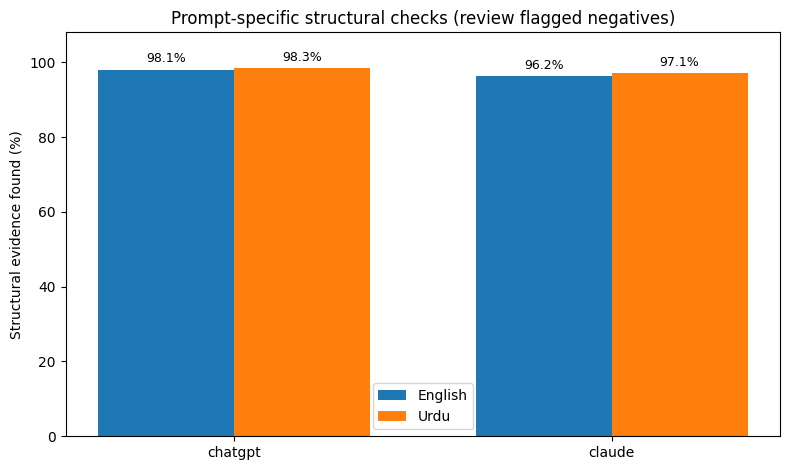

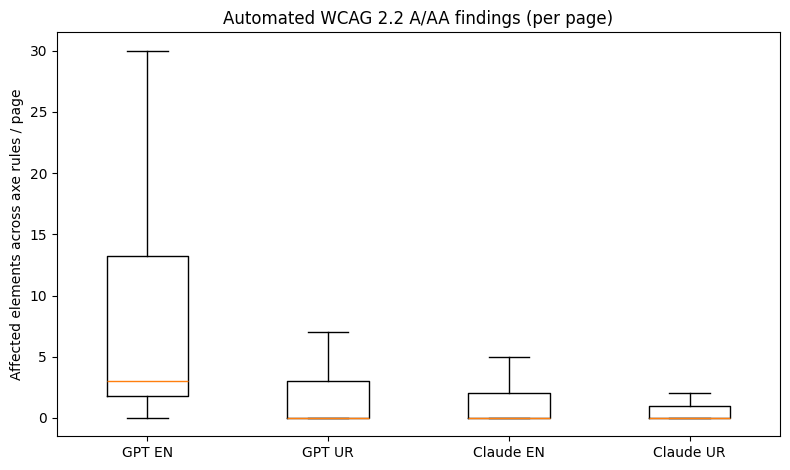

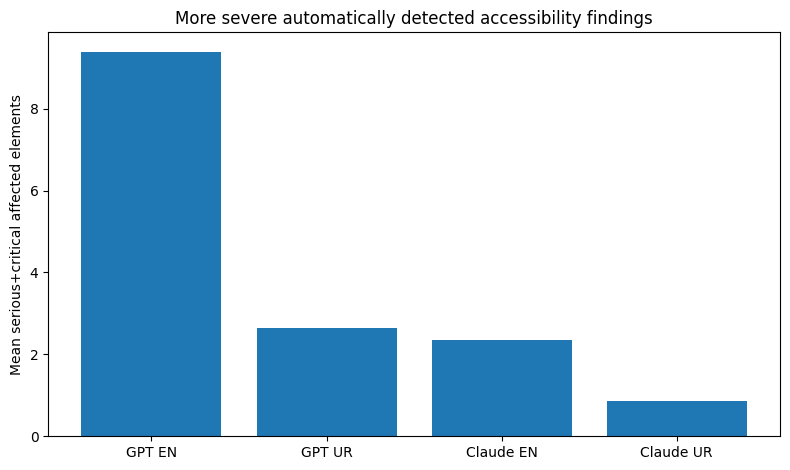

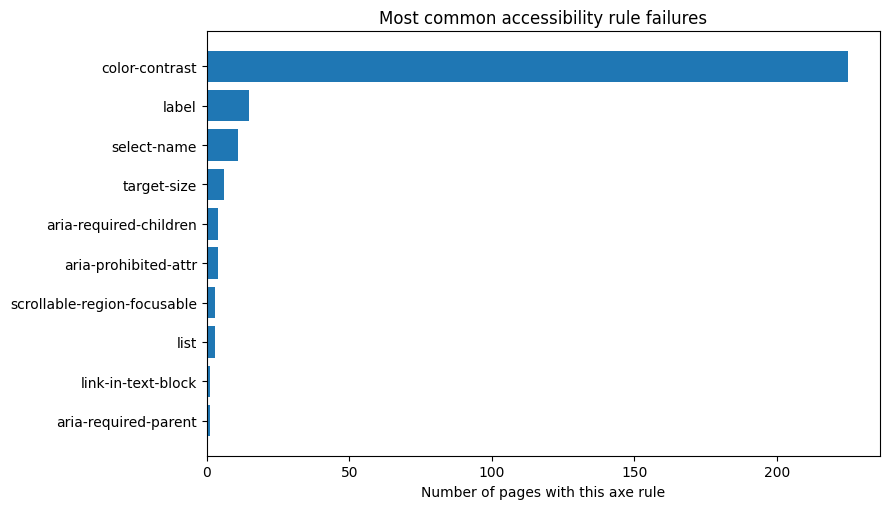

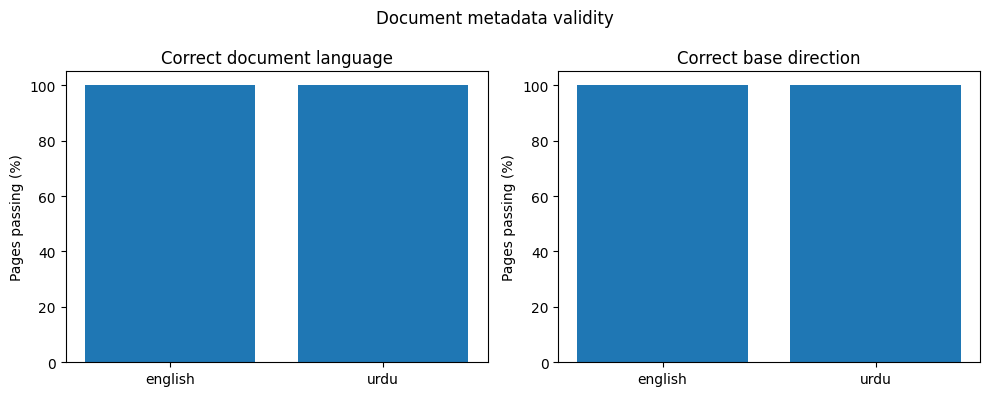

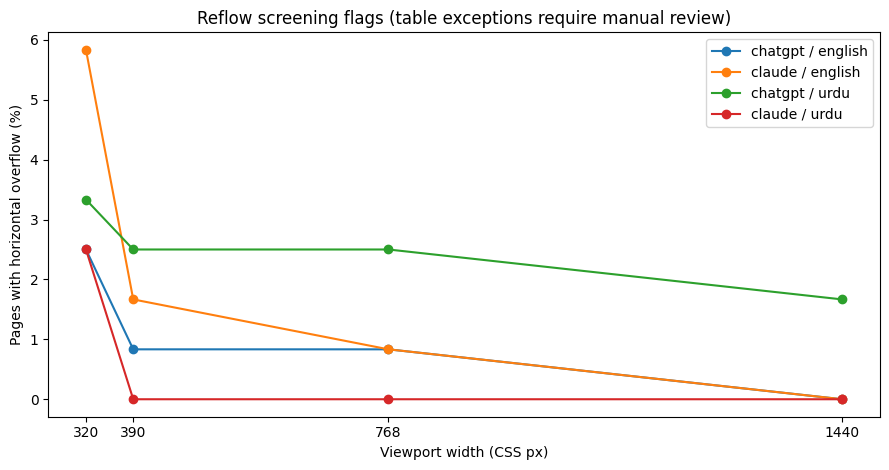

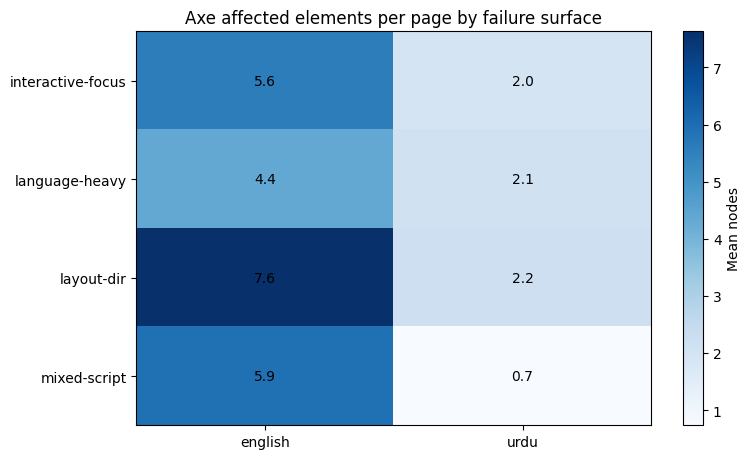

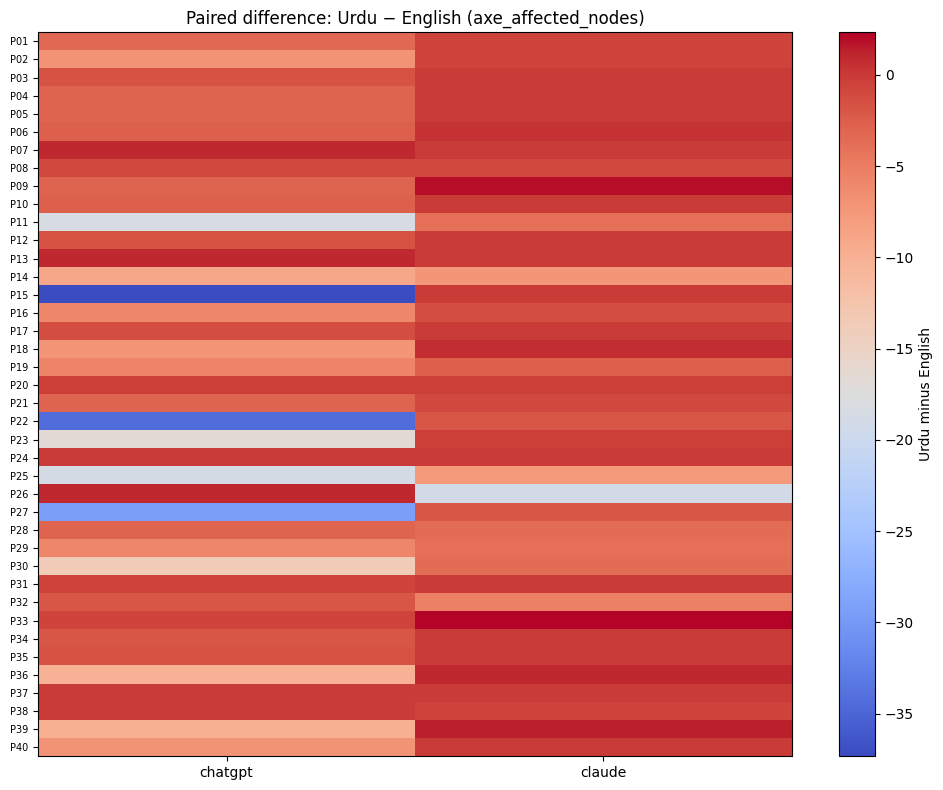

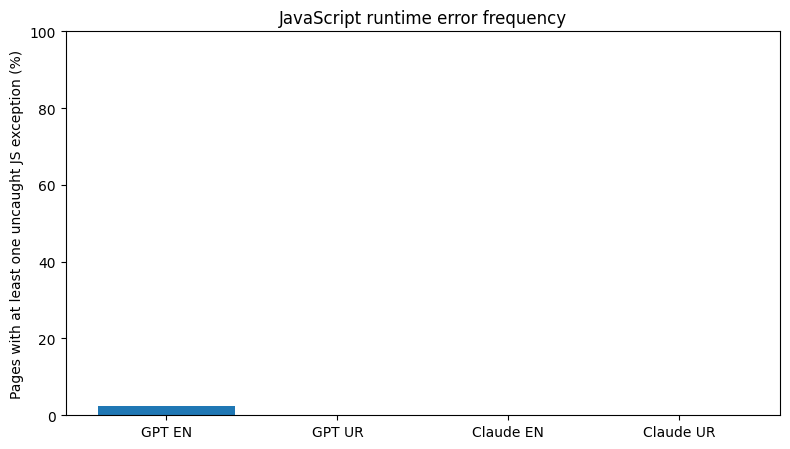


                  metric   model  n_paired_prompts  urdu_minus_english_mean  bootstrap_ci95_low  bootstrap_ci95_high                                                                                                  note
structural_evidence_pct chatgpt                40                 0.277778           -2.916667             3.333333 Exploratory paired bootstrap; prompt is the sampling unit; language and output locale are confounded.
structural_evidence_pct  claude                40                 0.833333           -3.750000             4.583333 Exploratory paired bootstrap; prompt is the sampling unit; language and output locale are confounded.

         metric   model  n_paired_prompts  urdu_minus_english_mean  bootstrap_ci95_low  bootstrap_ci95_high                                                                                                  note
axe_rule_count chatgpt                40                -0.325000           -0.491667        -1.500000e-01 Exploratory paired bootstr

In [10]:
CONFIG["MAX_PAGES"] = None        # Set 12 for quick smoke test; None for all 480
CONFIG["ENABLE_AXE"] = True
CONFIG["ENABLE_INTERACTION_SMOKE"] = True
CONFIG["ALLOW_EXTERNAL_RESOURCES"] = True
CONFIG["FORCE_INLINE_HTML"] = False    # Normal Colab: use local HTTP server
CONFIG["SAVE_SCREENSHOTS"] = False   # Set True for up to 24 balanced screenshots

# Colab/Jupyter has a running asyncio loop. Offload synchronous Playwright
# to a worker thread instead of invoking it on the notebook's event-loop thread.
import asyncio
RESULT = await asyncio.to_thread(run_all, base_dir="/content", config=CONFIG)

## Step 9 — Inspect evaluation coverage and group summaries

Always inspect **successful page loads and successful axe scans before interpreting condition means**. A failed test is not a score of zero. The structural percentage is only *presence-screening evidence*, not a complete functional-pass or prompt-compliance score.

In [11]:
from IPython.display import display
m = RESULT["metrics"]
display(m.groupby(["model","language"], dropna=False).agg(
    pages=("page_id","size"),
    loaded=("load_ok","sum"),
    axe_completed=("axe_status",lambda s: (s=="ok").sum()),
    structural_evidence_pct=("structural_evidence_pct","mean"),
    axe_rules_per_page=("axe_rule_count","mean"),
    affected_elements_per_page=("axe_affected_nodes","mean"),
    serious_critical_elements_per_page=("axe_serious_critical_nodes","mean"),
    js_exceptions_per_page=("js_exception_count","mean"),
).round(2))
print("Manual-review flags:",len(RESULT["review_queue"]))
print("Results directory:", RESULT["output_dir"])
print("Figures:", len(list((RESULT["output_dir"]/"figures").glob("*.png"))))

pages  loaded  axe_completed  structural_evidence_pct  \
model   language                                                          
chatgpt english     120     120            120                    98.06   
        urdu        120     120            120                    98.33   
claude  english     120     120            120                    96.25   
        urdu        120     120            120                    97.08   

                  axe_rules_per_page  affected_elements_per_page  \
model   language                                                   
chatgpt english                 0.91                        9.39   
        urdu                    0.58                        2.63   
claude  english                 0.48                        2.35   
        urdu                    0.31                        0.86   

                  serious_critical_elements_per_page  js_exceptions_per_page  
model   language                                                              
chatgpt english                                 9.39                    0.05  
        urdu                                    2.63                    0.00  
claude  english                                 2.35                    0.00  
        urdu                                    0.86                    0.00

Manual-review flags: 187
Results directory: /content/rtl_eval_results
Figures: 9


## Step 10 — Download complete results

A ZIP containing the figures, all tables, the audit README and the manual-review template is created automatically. Use `files.download` to transfer it to your computer.

In [12]:
from google.colab import files
files.download(str(RESULT["archive"]))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Interpretation checklist for your SE4All paper

1. Verify the **40 prompts × 2 languages × 2 models × 3 runs** design from `manifest.csv`.
2. Do **not** interpret a clean axe run as proof of WCAG conformance. Examine failures, incomplete rules and dynamic UI states.
3. Use `structural_requirement_checks.csv` as feature-detection evidence; manually confirm missing or custom-implemented UI components.
4. Use `balanced_manual_review_template.csv` for Urdu readability, bidirectional strings, responsive exceptions, functional workflows and focus management.
5. Compare English/Urdu **within each model and prompt**, report point differences and confidence intervals, then investigate categories/failure surfaces.
6. Disclose external resource policy, browser version, axe version, missing scans and the combined prompt-language/output-language design limitation.

**Technical references**: [WCAG 2.2](https://www.w3.org/TR/WCAG22/), [Deque axe-core API](https://www.deque.com/axe/core-documentation/api-documentation/), [Playwright Python](https://playwright.dev/python/docs/intro), [W3C Reflow Understanding](https://www.w3.org/WAI/WCAG22/Understanding/reflow.html), [Nu HTML Checker](https://validator.w3.org/nu/).